# Midsem Solutions & Fine-tuning IndicBERT for Language Identification
### Introduction to Large Language Models — Assignment 10

**Part A** solves questions 2, 4 and 5 of the midsem paper (beam search, BPE, TF-IDF / Doc2Vec). Each
answer is worked out by hand and then checked with a few lines of Python.

**Part B** fine-tunes a BERT-base model on the language identification (LID) dataset built in
Assignment 1 (23 Indian languages from IndicCorp v2) and compares it with the earlier models:
TF-IDF logistic regression (Assignment 1) and logistic regression, MLP, LSTM, GRU and FastText
classifiers (Assignment 6).

# Part A — Midsem questions 2, 4 and 5

## Question 2 — Beam search with beam width $k = 2$

Vocabulary $V = \{\text{cat}, \text{sat}, \text{mat}, \text{</s>}\}$. The score of a hypothesis is the
product of its conditional probabilities (cumulative probability). At each step every hypothesis in the
beam is expanded with every possible next token, and only the $k = 2$ highest-scoring hypotheses are kept.

**t = 1** (expand `<s>`):

| Hypothesis | Cumulative probability | Kept? |
|---|---|---|
| cat | 0.5 | ✅ |
| sat | 0.3 | ✅ |
| mat | 0.2 | ❌ (pruned) |

**t = 2** (expand `cat` and `sat`):

| Hypothesis | Cumulative probability | Kept? |
|---|---|---|
| cat sat | 0.5 × 0.6 = **0.30** | ✅ |
| cat mat | 0.5 × 0.3 = 0.15 | ❌ |
| cat `</s>` | 0.5 × 0.1 = 0.05 | ❌ |
| sat cat | 0.3 × 0.2 = 0.06 | ❌ |
| sat mat | 0.3 × 0.7 = **0.21** | ✅ |
| sat `</s>` | 0.3 × 0.1 = 0.03 | ❌ |

**t = 3** (expand `cat sat` and `sat mat`):

| Hypothesis | Cumulative probability | Kept? |
|---|---|---|
| cat sat mat | 0.30 × 0.8 = **0.240** | ✅ |
| cat sat `</s>` | 0.30 × 0.2 = 0.060 | ❌ |
| sat mat cat | 0.21 × 0.1 = 0.021 | ❌ |
| sat mat `</s>` | 0.21 × 0.9 = **0.189** | ✅ |

**Final output.** After the three steps the beam holds `cat sat mat` (0.240) and `sat mat </s>` (0.189).
The highest-scoring sequence is **"cat sat mat"** (probability 0.24).
If the decoder only accepts *finished* hypotheses (ending in `</s>`), the answer is
**"sat mat `</s>`"** (0.189), the only completed hypothesis in the final beam.

**Why we ignore P(cat | mat) and P(sat | mat):** the hypothesis `mat` had the lowest score at t = 1 (0.2)
and was pruned, because the beam keeps only 2 hypotheses. Beam search never expands a pruned
hypothesis, so probabilities conditioned on `mat` as the first word are never needed. That is also why
the question does not give them.

In [11]:
# Verify the trace: generic beam search over the given conditional probabilities
P = {
    ("<s>",): {"cat": 0.5, "sat": 0.3, "mat": 0.2},
    ("cat",): {"sat": 0.6, "mat": 0.3, "</s>": 0.1},
    ("sat",): {"cat": 0.2, "mat": 0.7, "</s>": 0.1},
    ("cat", "sat"): {"mat": 0.8, "</s>": 0.2},
    ("sat", "mat"): {"cat": 0.1, "</s>": 0.9},
}

def beam_search(P, k=2, steps=3):
    beam = [((), 1.0)]
    for t in range(1, steps + 1):
        expanded = []
        for seq, score in beam:
            context = seq if seq else ("<s>",)
            for w, p in P.get(context, {}).items():
                expanded.append((seq + (w,), score * p))
        expanded.sort(key=lambda x: -x[1])
        print(f"t={t}: " + ", ".join(f"{' '.join(s)}={p:.3f}" for s, p in expanded))
        beam = expanded[:k]
        print(f"      kept: " + ", ".join(f"{' '.join(s)}={p:.3f}" for s, p in beam))
    return beam

final = beam_search(P)
print("\nbest sequence:", " ".join(final[0][0]), f"({final[0][1]:.3f})")

t=1: cat=0.500, sat=0.300, mat=0.200
      kept: cat=0.500, sat=0.300
t=2: cat sat=0.300, sat mat=0.210, cat mat=0.150, sat cat=0.060, cat </s>=0.050, sat </s>=0.030
      kept: cat sat=0.300, sat mat=0.210
t=3: cat sat mat=0.240, sat mat </s>=0.189, cat sat </s>=0.060, sat mat cat=0.021
      kept: cat sat mat=0.240, sat mat </s>=0.189

best sequence: cat sat mat (0.240)


## Question 4 — Byte Pair Encoding (2 merges)

**Word frequencies** in the corpus:

| Word | low | lower | lowest | new | newest | widest |
|---|---|---|---|---|---|---|
| Count | 5 | 2 | 3 | 2 | 1 | 3 |

Each word is split into characters plus an end-of-word marker `_` (so that suffixes like `est_` can be
told apart from word-internal `est`):

`l o w _` (5), `l o w e r _` (2), `l o w e s t _` (3), `n e w _` (2), `n e w e s t _` (1), `w i d e s t _` (3)

**Initial vocabulary** (all characters): `{_, d, e, i, l, n, o, r, s, t, w}` — 11 symbols.

**Merge 1.** Count every adjacent symbol pair, weighted by word frequency:

| Pair | Count | Pair | Count |
|---|---|---|---|
| **(l, o)** | 5+2+3 = **10** | (n, e) | 2+1 = 3 |
| **(o, w)** | 5+2+3 = **10** | (e, w) | 2+1 = 3 |
| (w, \_) | 5+2 = 7 | (w, i) | 3 |
| (e, s) | 3+1+3 = 7 | (i, d) | 3 |
| (s, t) | 7 | (d, e) | 3 |
| (t, \_) | 7 | (e, r) | 2 |
| (w, e) | 2+3+1 = 6 | (r, \_) | 2 |

(l, o) and (o, w) tie at 10; we take the first one found, **(l, o) → `lo`**.

Corpus: `lo w _`, `lo w e r _`, `lo w e s t _`, `n e w _`, `n e w e s t _`, `w i d e s t _`

**Merge 2.** Now (lo, w) = 5+2+3 = **10** is the most frequent pair (next: (e, s), (s, t), (t, \_) = 7),
so **(lo, w) → `low`**.

Corpus: `low _`, `low e r _`, `low e s t _`, `n e w _`, `n e w e s t _`, `w i d e s t _`

(Breaking the first tie the other way gives (o, w) → `ow` and then (l, ow) → `low`, so the final tokens
are the same.)

**Merge rules (in order):** 1. `l o → lo`   2. `lo w → low`

**Final vocabulary:** `{_, d, e, i, l, n, o, r, s, t, w, lo, low}` — 13 symbols.

**Out-of-vocabulary words.** BPE never sees a truly unknown word: a new word is split into characters
(plus `_`) and the learned merges are applied **in the same order** as during training. For example,
`slower` → `s l o w e r _` → (rule 1) `s lo w e r _` → (rule 2) `s low e r _`. The word is represented by
known subwords (`low`, `e`, `r`, …). Only a character never seen in training becomes `<unk>`. With more
merges, frequent pieces such as `est_` would also become single tokens, so `newest`/`widest`/`lowest`
would share the suffix token.

In [12]:
from collections import Counter

corpus = '''low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest'''

word_freq = Counter(corpus.split())
print("word frequencies:", dict(word_freq))
words = {tuple(w) + ("_",): c for w, c in word_freq.items()}

def pair_counts(words):
    pairs = Counter()
    for symbols, c in words.items():
        for a, b in zip(symbols, symbols[1:]):
            pairs[(a, b)] += c
    return pairs

def merge(words, pair):
    out = {}
    for symbols, c in words.items():
        s, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
                s.append(symbols[i] + symbols[i + 1]); i += 2
            else:
                s.append(symbols[i]); i += 1
        out[tuple(s)] = c
    return out

vocab = sorted({ch for w in words for ch in w})
print("initial vocabulary:", vocab)
rules = []
for step in (1, 2):
    pairs = pair_counts(words)
    best = max(pairs, key=pairs.get)          # first pair with the highest count
    print(f"\nmerge {step}: top pairs {pairs.most_common(4)} -> merge {best}")
    words = merge(words, best)
    rules.append(best)
    vocab.append("".join(best))
    for w, c in words.items():
        print(f"   {' '.join(w):18s} x{c}")
print("\nmerge rules:", [f"{a} {b} -> {a + b}" for a, b in rules])
print("final vocabulary:", vocab)

def bpe_encode(word):
    symbols = tuple(word) + ("_",)
    for pair in rules:
        symbols = tuple(merge({symbols: 1}, pair))[0]
    return symbols

print("\nOOV example 'slower' ->", bpe_encode("slower"))

word frequencies: {'low': 5, 'lower': 2, 'lowest': 3, 'new': 2, 'newest': 1, 'widest': 3}
initial vocabulary: ['_', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']

merge 1: top pairs [(('l', 'o'), 10), (('o', 'w'), 10), (('w', '_'), 7), (('e', 's'), 7)] -> merge ('l', 'o')
   lo w _             x5
   lo w e r _         x2
   lo w e s t _       x3
   n e w _            x2
   n e w e s t _      x1
   w i d e s t _      x3

merge 2: top pairs [(('lo', 'w'), 10), (('w', '_'), 7), (('e', 's'), 7), (('s', 't'), 7)] -> merge ('lo', 'w')
   low _              x5
   low e r _          x2
   low e s t _        x3
   n e w _            x2
   n e w e s t _      x1
   w i d e s t _      x3

merge rules: ['l o -> lo', 'lo w -> low']
final vocabulary: ['_', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', 'lo', 'low']

OOV example 'slower' -> ('s', 'low', 'e', 'r', '_')


## Question 5 — TF-IDF, class representations, and Doc2Vec

| Doc | Text | Class |
|---|---|---|
| D1 | machine learning is useful | Technology |
| D2 | machine learning is powerful | Technology |
| D3 | learning language is useful | Language |
| D4 | language processing is useful | Language |

**Vocabulary** (7 words): `{machine, learning, is, useful, powerful, language, processing}`

**Formulas** ($N = 4$ documents):
$\text{TF}(t, d) = \dfrac{\text{count}(t, d)}{|d|}$,
$\text{IDF}(t) = \log_{10}\dfrac{N}{\text{df}(t)}$,
$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t)$.

Every document has 4 words and no word repeats inside a document, so TF = 1/4 = 0.25 for each word
present (0 otherwise).

| Word | df | IDF = log₁₀(4/df) | TF-IDF where present (0.25 × IDF) |
|---|---|---|---|
| machine | 2 | 0.3010 | 0.0753 |
| learning | 3 | 0.1249 | 0.0312 |
| is | 4 | 0.0000 | 0.0000 |
| useful | 3 | 0.1249 | 0.0312 |
| powerful | 1 | 0.6021 | 0.1505 |
| language | 2 | 0.3010 | 0.0753 |
| processing | 1 | 0.6021 | 0.1505 |

**TF-IDF document vectors:**

| Doc | machine | learning | is | useful | powerful | language | processing |
|---|---|---|---|---|---|---|---|
| D1 | 0.0753 | 0.0312 | 0 | 0.0312 | 0 | 0 | 0 |
| D2 | 0.0753 | 0.0312 | 0 | 0 | 0.1505 | 0 | 0 |
| D3 | 0 | 0.0312 | 0 | 0.0312 | 0 | 0.0753 | 0 |
| D4 | 0 | 0 | 0 | 0.0312 | 0 | 0.0753 | 0.1505 |

"is" appears in every document, so its IDF and TF-IDF are 0: it carries no information. Rare words
("powerful", "processing") get the highest weights.

**Representing the classes.** Each class is represented by the **centroid** (mean) of the TF-IDF vectors
of its documents (the Rocchio / nearest-centroid method):

| Class | machine | learning | is | useful | powerful | language | processing |
|---|---|---|---|---|---|---|---|
| Technology = (D1 + D2) / 2 | 0.0753 | 0.0312 | 0 | 0.0156 | 0.0753 | 0 | 0 |
| Language = (D3 + D4) / 2 | 0 | 0.0156 | 0 | 0.0312 | 0 | 0.0753 | 0.0753 |

A new document is converted to a TF-IDF vector with the same vocabulary and IDF values, and assigned to
the class whose centroid has the highest **cosine similarity** with it. "machine" and "powerful" point to
Technology; "language" and "processing" point to Language. (An alternative is to merge each class's
documents into one class document and compute TF-IDF over the 2 class documents.)

**Learning document representations with Doc2Vec.** The technique is **Paragraph Vectors** (Le &
Mikolov, 2014), in two variants:

**PV-DM (Distributed Memory)** — the paragraph vector and the context word vectors together predict the
next/centre word:

```
 Doc ID (one-hot, 4 docs)      context words: "machine"  "learning"  "is"
          │                                     │          │          │
          ▼                                     ▼          ▼          ▼
 ┌──────────────────┐                  ┌──────────────────────────────────┐
 │ D (4 × d) matrix │                  │   W (|V| × d) shared word matrix │
 └────────┬─────────┘                  └──────┬──────────┬──────────┬─────┘
          │ paragraph vector d_D1             │ w_mach   │ w_learn  │ w_is
          └───────────────┬───────────────────┴──────────┴──────────┘
                          ▼
             average / concatenate  (hidden layer, size d or 4d)
                          ▼
             softmax over vocabulary  (|V| = 7)
                          ▼
                 predict target word: "useful"
```

**PV-DBOW (Distributed Bag of Words)** — the paragraph vector alone predicts words sampled from the
document (like skip-gram, with the document ID as the input):

```
 Doc ID D1 (one-hot) ──► D matrix ──► paragraph vector d_D1 ──► softmax over |V| ──► predict
                                                                                    "machine", "learning",
                                                                                    "is", "useful"
```

**Training:** the word vectors W, the paragraph vectors D and the softmax weights are learned together
by SGD (with negative sampling or hierarchical softmax) to maximise the probability of the target words.
The learned row of D for each document is its representation. **For a new document**, W and the softmax
weights are frozen and only a new paragraph vector is trained by gradient descent (the *inference step*).
The 4 document vectors can then be averaged per class or fed to a classifier, just like the TF-IDF vectors.

In [13]:
import math
import pandas as pd

docs = {"D1": "machine learning is useful", "D2": "machine learning is powerful",
        "D3": "learning language is useful", "D4": "language processing is useful"}
classes = {"D1": "Technology", "D2": "Technology", "D3": "Language", "D4": "Language"}
vocab = ["machine", "learning", "is", "useful", "powerful", "language", "processing"]
N = len(docs)

df = {w: sum(w in d.split() for d in docs.values()) for w in vocab}
idf = {w: math.log10(N / df[w]) for w in vocab}
tfidf = pd.DataFrame({name: {w: text.split().count(w) / len(text.split()) * idf[w] for w in vocab}
                      for name, text in docs.items()}).T[vocab]

print(pd.DataFrame({"df": df, "idf (log10)": idf}).round(4))
print("\nTF-IDF matrix:")
print(tfidf.round(4))
print("\nClass centroids:")
print(tfidf.groupby(pd.Series(classes)).mean().round(4))

            df  idf (log10)
machine      2       0.3010
learning     3       0.1249
is           4       0.0000
useful       3       0.1249
powerful     1       0.6021
language     2       0.3010
processing   1       0.6021

TF-IDF matrix:
    machine  learning   is  useful  powerful  language  processing
D1   0.0753    0.0312  0.0  0.0312    0.0000    0.0000      0.0000
D2   0.0753    0.0312  0.0  0.0000    0.1505    0.0000      0.0000
D3   0.0000    0.0312  0.0  0.0312    0.0000    0.0753      0.0000
D4   0.0000    0.0000  0.0  0.0312    0.0000    0.0753      0.1505

Class centroids:
            machine  learning   is  useful  powerful  language  processing
Language     0.0000    0.0156  0.0  0.0312    0.0000    0.0753      0.0753
Technology   0.0753    0.0312  0.0  0.0156    0.0753    0.0000      0.0000


# Part B — Fine-tuning a BERT model for language identification

**Dataset.** The Assignment 1 splits: 1,000 sentences per language for 23 Indian languages from
IndicCorp v2, split 80/10/10 per language (18,400 train / 2,300 validation / 2,300 test sentences).

**Model.** [IndicBERT v2](https://huggingface.co/ai4bharat/IndicBERTv2-MLM-only)
(`ai4bharat/IndicBERTv2-MLM-only`, AI4Bharat), a **BERT-base** encoder (12 layers, hidden size 768,
≈278M parameters, most of them in the 250k-token embedding table) pretrained with masked language
modelling on IndicCorp v2. We chose it over mBERT, MuRIL and XLM-RoBERTa because it is the only one that
covers **all 23 languages** in our dataset: the others lack some of them, e.g. Bodo, Santali, Khasi,
Meitei, Dogri. A classification head (linear layer over the `[CLS]` representation) is added and the whole
model is fine-tuned with cross-entropy loss.

> **Caveat.** IndicBERT v2 was pretrained on IndicCorp v2, the corpus our sentences come from, so it may
> have seen some test sentences as unlabelled text during pretraining. It never saw the language labels,
> but this familiarity may make its scores slightly optimistic.

**Comparison.** Assignment 1's TF-IDF logistic regression used all **23** languages. Assignment 6's models
used only the **18** languages that have pretrained FastText vectors. So IndicBERT is evaluated on both:
the full 23-language test set, and the same 1,800-sentence 18-language subset that Assignment 6 used
(rows in the same order, so predictions can be compared one by one).

## 0. Setup

In [14]:
# %pip install -q transformers accelerate pandas pyarrow matplotlib

In [15]:
import os
import pickle
import random
import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from torch.utils.data import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

print("torch", torch.__version__, "| transformers", transformers.__version__)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
set_seed(RANDOM_SEED)

LAB1_SPLITS = "../Lab-1/splits"
LAB1_REPORT = "../Lab-1/artifacts/test_classification_report.csv"
LAB6_RESULTS = "../Lab-6/lab6_artifacts/classifier_comparison.csv"
LAB6_PREDS = "../Lab-6/lab6_artifacts/test_predictions.pkl"
ARTIFACTS_DIR = "lab10_artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
MAX_LEN = 128          # covers >99% of sentences (checked below)
EPOCHS = 3
BATCH_SIZE = 32
LEARNING_RATE = 3e-5

# Languages Assignment 6 kept (those with pretrained FastText wiki vectors)
LAB6_EXCLUDED = ["brx_Deva", "doi_Deva", "khasi", "mni_Mtei", "santhali"]

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"     # Apple-silicon GPU
else:
    DEVICE = "cpu"
ON_MPS = DEVICE == "mps"

# Apple-silicon (MPS) settings: the GPU shares the Mac's 16 GB of RAM, and full fine-tuning of this
# 278M-parameter model does not fit, so it swaps and the GPU sits idle. On MPS we therefore:
FREEZE_EMBEDDINGS = ON_MPS          # keep the 250k x 768 token-embedding table (192M params) frozen
BATCH_SIZE = 16 if ON_MPS else 32   # smaller batches ...
GRAD_ACCUM = 2 if ON_MPS else 1     # ... with gradient accumulation, so the effective batch is still 32
PAD_MULTIPLE = 32 if ON_MPS else None  # few distinct tensor shapes -> less MPS memory fragmentation
print("device:", DEVICE, "| freeze embeddings:", FREEZE_EMBEDDINGS,
      "| batch:", BATCH_SIZE, "x", GRAD_ACCUM, "accumulation")

torch 2.14.0 | transformers 5.23.0
device: mps | freeze embeddings: True | batch: 16 x 2 accumulation


## 1. Load the Assignment 1 dataset

In [16]:
train_df = pd.read_parquet(f"{LAB1_SPLITS}/train.parquet")
val_df = pd.read_parquet(f"{LAB1_SPLITS}/val.parquet")
test_df = pd.read_parquet(f"{LAB1_SPLITS}/test.parquet")

LABELS = sorted(train_df["label"].unique())
LABEL2IDX = {lab: i for i, lab in enumerate(LABELS)}
IDX2LABEL = {i: lab for lab, i in LABEL2IDX.items()}
N_CLASSES = len(LABELS)

print(f"train: {train_df.shape}  val: {val_df.shape}  test: {test_df.shape}  classes: {N_CLASSES}")
pd.DataFrame({name: d.label.value_counts() for name, d in
              [("train", train_df), ("val", val_df), ("test", test_df)]}).T

train: (18400, 4)  val: (2300, 4)  test: (2300, 4)  classes: 23


label,asm_Beng,ben_Beng,brx_Deva,doi_Deva,gom_Deva,guj_Gujr,hin_Deva,kan_Knda,kas_Arab,khasi,...,mni_Mtei,npi_Deva,ory_Orya,pan_Guru,san_Deva,santhali,snd_Deva,tam_Taml,tel_Telu,urd_Arab
train,800,800,800,800,800,800,800,800,800,800,...,800,800,800,800,800,800,800,800,800,800
val,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,100
test,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,100


## 2. Tokenisation

IndicBERT v2 uses a 250k-token WordPiece vocabulary shared across all 23 languages and English. We check
how long the sentences are in tokens and how often the tokenizer falls back to `[UNK]` for each language.

In [17]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

enc_train = tokenizer(list(train_df.text), truncation=False)["input_ids"]
lens = np.array([len(x) for x in enc_train])
print("tokens per sentence: mean %.1f | median %d | 95th %d | 99th %d | max %d"
      % (lens.mean(), np.median(lens), np.percentile(lens, 95), np.percentile(lens, 99), lens.max()))
print(f"sentences longer than MAX_LEN={MAX_LEN}: {(lens > MAX_LEN).mean() * 100:.2f}% (truncated)")

unk = tokenizer.unk_token_id
unk_rate = (train_df.assign(unk=[sum(i == unk for i in x) / len(x) for x in enc_train])
            .groupby("label").unk.mean().mul(100).round(2))
print("\n[UNK] rate per language (% of tokens):")
print(unk_rate.sort_values(ascending=False).head(8).to_string())
print("\nexample:", train_df.text.iloc[0], "\n ->", tokenizer.tokenize(train_df.text.iloc[0]))
del enc_train

tokens per sentence: mean 25.3 | median 20 | 95th 60 | 99th 95 | max 239
sentences longer than MAX_LEN=128: 0.31% (truncated)

[UNK] rate per language (% of tokens):
label
asm_Beng    0.0
mar_Deva    0.0
tel_Telu    0.0
tam_Taml    0.0
snd_Deva    0.0
santhali    0.0
san_Deva    0.0
pan_Guru    0.0

example: ਇਸ ਵਾਰਡ ਵਿੱਚ ਆਜਾਦ ਗਰੁੱਪ ਦੇ ਉਮੀਦਵਾਰ ਅਤੇ ਸਾਬਕਾ ਕੌਂਸਲਰ ਸzy ਸੁਰਿੰਦਰ ਸਿੰਘ ਰੋਡਾ ਅਤੇ ਕਾਂਗਰਸ ਪਾਰਟੀ ਦੇ ਉਮੀਦਵਾਰ ਹਰਜੀਤ ਸਿੰਘ ਬੈਦਵਾਨ ਵਿਚਾਲੇ ਟੱਕਰ ਹੈ। 
 -> ['ਇਸ', 'ਵਾਰਡ', 'ਵਿੱਚ', 'ਆ', '##ਜਾ', '##ਦ', 'ਗਰੁੱਪ', 'ਦੇ', 'ਉਮੀਦਵਾਰ', 'ਅਤੇ', 'ਸਾਬਕਾ', 'ਕੌਂਸਲਰ', 'ਸ', '##zy', 'ਸੁਰਿੰਦਰ', 'ਸਿੰਘ', 'ਰੋਡ', '##ਾ', 'ਅਤੇ', 'ਕਾਂਗਰਸ', 'ਪਾਰਟੀ', 'ਦੇ', 'ਉਮੀਦਵਾਰ', 'ਹਰਜੀਤ', 'ਸਿੰਘ', 'ਬੈ', '##ਦ', '##ਵਾਨ', 'ਵਿਚਾਲੇ', 'ਟੱਕਰ', 'ਹੈ', '।']


In [18]:
class LIDDataset(Dataset):
    def __init__(self, df):
        self.enc = tokenizer(list(df.text), truncation=True, max_length=MAX_LEN)
        self.labels = df.label.map(LABEL2IDX).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

train_ds, val_ds, test_ds = LIDDataset(train_df), LIDDataset(val_df), LIDDataset(test_df)
print(len(train_ds), len(val_ds), len(test_ds))

18400 2300 2300


## 3. Metrics

Accuracy and **macro-F1** (the mean of the per-class F1 scores), computed from scratch exactly as in
Assignments 1 and 6, so the numbers are directly comparable.

In [19]:
def precision_recall_f1_per_class(y_true, y_pred, n_classes):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    precisions, recalls, f1s = [], [], []
    for c in range(n_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
        precisions.append(precision); recalls.append(recall); f1s.append(f1)
    return np.array(precisions), np.array(recalls), np.array(f1s)


def macro_f1_score(y_true, y_pred, n_classes):
    _, _, f1s = precision_recall_f1_per_class(y_true, y_pred, n_classes)
    return float(np.mean(f1s)), f1s


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"accuracy": float((preds == labels).mean()),
            "macro_f1": macro_f1_score(labels, preds, N_CLASSES)[0]}

## 4. Fine-tune IndicBERT v2

Standard BERT fine-tuning recipe: AdamW, learning rate 3e-5 with linear decay and 10% warm-up,
weight decay 0.01, effective batch size 32, 3 epochs. Batches group sentences of similar length to cut
padding. The model is evaluated on the validation set after every epoch, and the epoch with the best
validation macro-F1 is kept.

**Apple-silicon (MPS) setup.** Full fine-tuning needs the weights, gradients and two AdamW states for
all 278M parameters (≈4.5 GB) plus activations. On a 16 GB Mac, where the GPU shares system RAM, this
fills memory and swaps, leaving the GPU almost idle. On MPS the notebook therefore:
- **freezes the token-embedding table** (250k × 768 = 192M parameters, 69% of the model), so only the 12
  Transformer layers and the classifier (~86M parameters) are trained. That removes ≈2.3 GB of
  gradients and optimizer state and the costly update of the full table every step. LID mostly needs
  the encoder layers to adapt; the pretrained token vectors already separate scripts and languages well;
- uses **batch size 16 with 2-step gradient accumulation** (same effective batch of 32, half the
  activation memory);
- pads each batch to a **multiple of 32 tokens**, so the GPU sees only a few tensor shapes;
- **empties the MPS cache** every 50 steps.

On a CUDA GPU the full model is fine-tuned with batch size 32 and fp16.

In [20]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=N_CLASSES, id2label=IDX2LABEL, label2id=LABEL2IDX)
if FREEZE_EMBEDDINGS:
    model.bert.embeddings.word_embeddings.weight.requires_grad_(False)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M | "
      f"trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:.1f}M")

args = TrainingArguments(
    output_dir=f"{ARTIFACTS_DIR}/indicbert_checkpoints",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=0.1,                          # float = fraction of total steps
    train_sampling_strategy="group_by_length",  # batch similar-length sentences to reduce padding
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=50,
    fp16=DEVICE == "cuda",
    dataloader_pin_memory=DEVICE == "cuda",
    torch_empty_cache_steps=50 if ON_MPS else None,   # release cached MPS memory regularly
    report_to="none",
    seed=RANDOM_SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer, pad_to_multiple_of=PAD_MULTIPLE),
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

t0 = time.time()
train_result = trainer.train()
print(f"training time: {(time.time() - t0) / 60:.1f} min")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 50429.97it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

parameters: 278.1M | trainable: 86.1M


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 3}.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.235009,0.095047,0.973478,0.973380
2,0.139449,0.084463,0.976522,0.976501
3,0.123038,0.085096,0.978696,0.978674


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.76s/it]


training time: 24.8 min


 epoch  eval_loss  eval_accuracy  eval_macro_f1
   1.0     0.0950         0.9735         0.9734
   2.0     0.0845         0.9765         0.9765
   3.0     0.0851         0.9787         0.9787


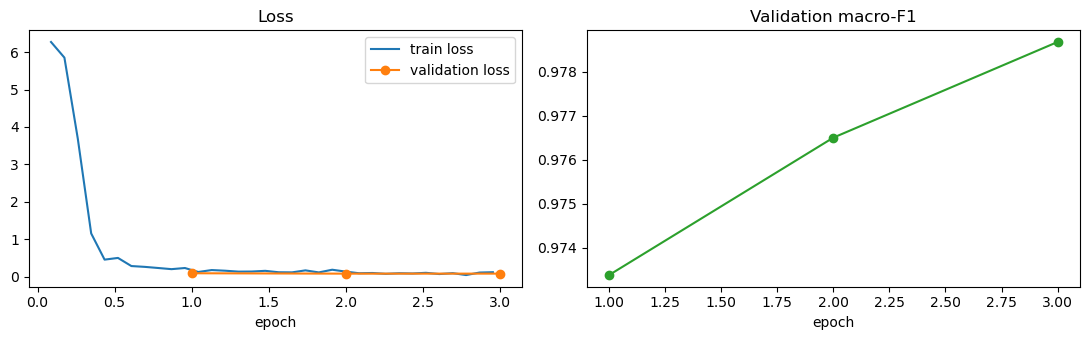

In [21]:
hist = pd.DataFrame(trainer.state.log_history)
val = hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
print(val.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
if "loss" in hist:   # training loss is logged every `logging_steps` steps
    train_loss = hist.dropna(subset=["loss"])
    axes[0].plot(train_loss.epoch, train_loss.loss, label="train loss")
axes[0].plot(val.epoch, val.eval_loss, "o-", label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(val.epoch, val.eval_macro_f1, "o-", color="tab:green")
axes[1].set_xlabel("epoch"); axes[1].set_title("Validation macro-F1")
plt.tight_layout(); plt.show()

## 5. Test-set evaluation (all 23 languages)

In [31]:
# group_by_length also reorders the eval/predict dataloader in transformers 5, which would shuffle
# predictions relative to test_ds.labels -> switch to sequential order before predicting.
trainer.args.train_sampling_strategy = "sequential"
pred_out = trainer.predict(test_ds)
test_logits = pred_out.predictions
y_test = np.array(test_ds.labels)
assert (pred_out.label_ids == y_test).all(), "prediction order does not match test_ds order"
y_pred = test_logits.argmax(-1)

bert_acc = float((y_pred == y_test).mean())
bert_f1, bert_per_class_f1 = macro_f1_score(y_test, y_pred, N_CLASSES)
print(f"IndicBERT v2 — test accuracy: {bert_acc:.4f} | test macro-F1: {bert_f1:.4f}")

prec, rec, f1s = precision_recall_f1_per_class(y_test, y_pred, N_CLASSES)
report = pd.DataFrame({"precision": prec, "recall": rec, "f1": f1s, "support": np.bincount(y_test, minlength=N_CLASSES)},
                      index=LABELS)
report.sort_values("f1").round(4)

IndicBERT v2 — test accuracy: 0.9813 | test macro-F1: 0.9813


,precision,recall,f1,support
gom_Deva,0.8056,0.87,0.8365,100
mar_Deva,0.8913,0.82,0.8542,100
hin_Deva,0.9333,0.98,0.9561,100
brx_Deva,0.9895,0.94,0.9641,100
khasi,0.9802,0.99,0.9851,100
mai_Deva,1.0000,0.98,0.9899,100
doi_Deva,0.9900,0.99,0.9900,100
san_Deva,0.9901,1.00,0.9950,100
asm_Beng,1.0000,1.00,1.0000,100
tam_Taml,1.0000,1.00,1.0000,100


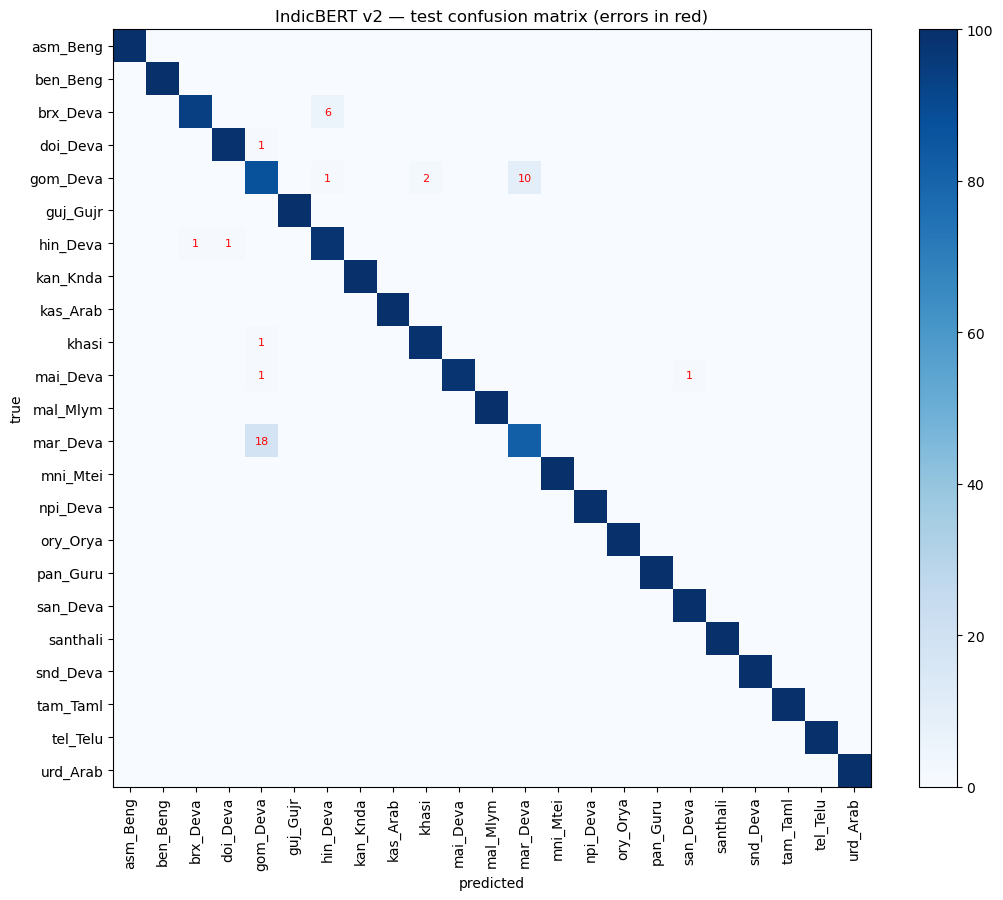

most common confusions (true -> predicted):
(mar_Deva, gom_Deva)    18
(gom_Deva, mar_Deva)    10
(brx_Deva, hin_Deva)     6
(gom_Deva, khasi)        2
(hin_Deva, doi_Deva)     1
(gom_Deva, hin_Deva)     1
(hin_Deva, brx_Deva)     1
(khasi, gom_Deva)        1
(mai_Deva, gom_Deva)     1
(mai_Deva, san_Deva)     1


In [32]:
cm = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
for t, p in zip(y_test, y_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(N_CLASSES), LABELS, rotation=90); ax.set_yticks(range(N_CLASSES), LABELS)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j] and i != j:
            ax.text(j, i, cm[i, j], ha="center", va="center", color="red", fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("IndicBERT v2 — test confusion matrix (errors in red)")
plt.colorbar(im); plt.tight_layout(); plt.show()

errors = [(IDX2LABEL[t], IDX2LABEL[p]) for t, p in zip(y_test, y_pred) if t != p]
print("most common confusions (true -> predicted):")
print(pd.Series(errors).value_counts().head(10).to_string())

## 6. Comparison with the earlier models

### 6.1 All 23 languages — vs Assignment 1 (TF-IDF + logistic regression)

In [33]:
lab1 = pd.read_csv(LAB1_REPORT, index_col=0)
lab1_f1 = float(lab1.loc["MACRO AVG", "f1"])
lab1_acc = float(lab1.loc[LABELS, "recall"].mean())   # equal support per class: accuracy = mean recall

full = pd.DataFrame({
    "test accuracy": {"TF-IDF + Logistic Regression (Lab 1)": lab1_acc, "IndicBERT v2 (fine-tuned)": bert_acc},
    "test macro-F1": {"TF-IDF + Logistic Regression (Lab 1)": lab1_f1, "IndicBERT v2 (fine-tuned)": bert_f1},
}).round(4)
full

,test accuracy,test macro-F1
TF-IDF + Logistic Regression (Lab 1),0.9461,0.9454
IndicBERT v2 (fine-tuned),0.9813,0.9813


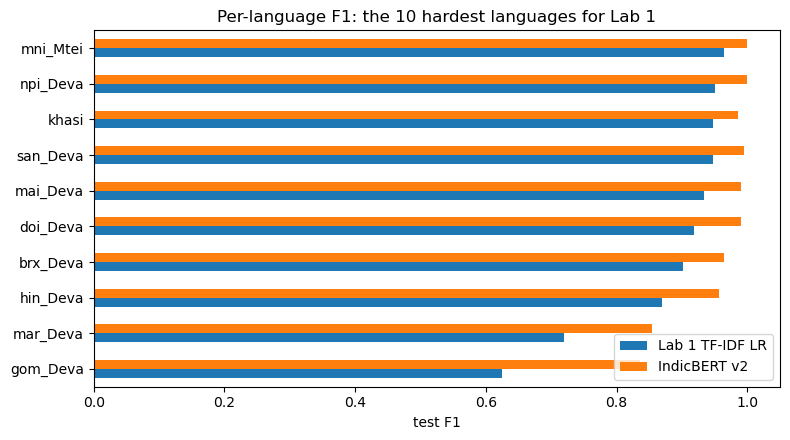

,Lab 1 TF-IDF LR,IndicBERT v2,difference
gom_Deva,0.625,0.837,0.212
mar_Deva,0.719,0.854,0.135
hin_Deva,0.869,0.956,0.087
brx_Deva,0.901,0.964,0.063
doi_Deva,0.918,0.990,0.072
mai_Deva,0.933,0.990,0.057
san_Deva,0.947,0.995,0.048
khasi,0.948,0.985,0.037
npi_Deva,0.950,1.000,0.050
mni_Mtei,0.964,1.000,0.036


In [34]:
per_class = pd.DataFrame({"Lab 1 TF-IDF LR": lab1.loc[LABELS, "f1"].astype(float),
                          "IndicBERT v2": pd.Series(bert_per_class_f1, index=LABELS)})
per_class["difference"] = per_class["IndicBERT v2"] - per_class["Lab 1 TF-IDF LR"]
hard = per_class.sort_values("Lab 1 TF-IDF LR").head(10)

ax = hard[["Lab 1 TF-IDF LR", "IndicBERT v2"]].plot.barh(figsize=(8, 4.5))
ax.set_xlabel("test F1"); ax.set_title("Per-language F1: the 10 hardest languages for Lab 1")
plt.tight_layout(); plt.show()
per_class.round(3).sort_values("Lab 1 TF-IDF LR")

### 6.2 The 18-language subset — vs Assignment 6 (LR, MLP, LSTM, GRU, FastText)

Assignment 6 removed 5 languages that have no FastText vectors. We take the same 1,800 test sentences (in
the same order) and score IndicBERT in two ways:

- **open set (23-way):** the fine-tuned model's normal prediction. Predicting one of the 5 removed
  languages counts as an error, so this is slightly harder than the task Assignment 6 solved.
- **closed set (18-way):** the argmax is taken only over the 18 languages, which is exactly the
  task Assignment 6's models solved.

In [35]:
lab6_labels = [lab for lab in LABELS if lab not in LAB6_EXCLUDED]
lab6_idx = {lab: i for i, lab in enumerate(lab6_labels)}
mask = test_df.label.isin(lab6_labels).to_numpy()
y_sub = test_df.label[mask].map(lab6_idx).to_numpy()

to_sub = np.array([lab6_idx.get(lab, -1) for lab in LABELS])     # 23-way index -> 18-way index (-1 = removed language)
open_pred = to_sub[y_pred[mask]]
keep_cols = [LABEL2IDX[lab] for lab in lab6_labels]
closed_pred = test_logits[mask][:, keep_cols].argmax(-1)

with open(LAB6_PREDS, "rb") as f:
    lab6_preds = pickle.load(f)

rows = []
for name, pred in lab6_preds.items():
    rows.append({"model": f"{name} (Lab 6)", "test accuracy": float((pred == y_sub).mean()),
                 "test macro-F1": macro_f1_score(y_sub, pred, len(lab6_labels))[0]})
for name, pred in [("IndicBERT v2 — open set, 23-way", open_pred), ("IndicBERT v2 — closed set, 18-way", closed_pred)]:
    rows.append({"model": name, "test accuracy": float((pred == y_sub).mean()),
                 "test macro-F1": macro_f1_score(y_sub, pred, len(lab6_labels))[0]})
comparison = pd.DataFrame(rows).sort_values("test macro-F1", ascending=False).reset_index(drop=True)
print(f"{mask.sum()} test sentences, {len(lab6_labels)} languages")
comparison.round(4)

1800 test sentences, 18 languages


,model,test accuracy,test macro-F1
0,"IndicBERT v2 — closed set, 18-way",0.9822,0.9822
1,"IndicBERT v2 — open set, 23-way",0.9806,0.9816
2,LSTM (Lab 6),0.9494,0.9491
3,GRU (Lab 6),0.9467,0.9466
4,MLP(n_hidden=2) (Lab 6),0.9400,0.9402
5,LogisticRegression (Lab 6),0.9372,0.9374
6,MLP(n_hidden=1) (Lab 6),0.9367,0.9361
7,FastText (Lab 6),0.8967,0.9003


In [36]:
# sanity check: our recomputed Lab 6 scores match the numbers saved in Assignment 6
print(pd.read_csv(LAB6_RESULTS).round(4).to_string(index=False))

        classifier  test_accuracy  test_macro_f1
              LSTM         0.9494         0.9491
               GRU         0.9467         0.9466
   MLP(n_hidden=2)         0.9400         0.9402
LogisticRegression         0.9372         0.9374
   MLP(n_hidden=1)         0.9367         0.9361
          FastText         0.8967         0.9003


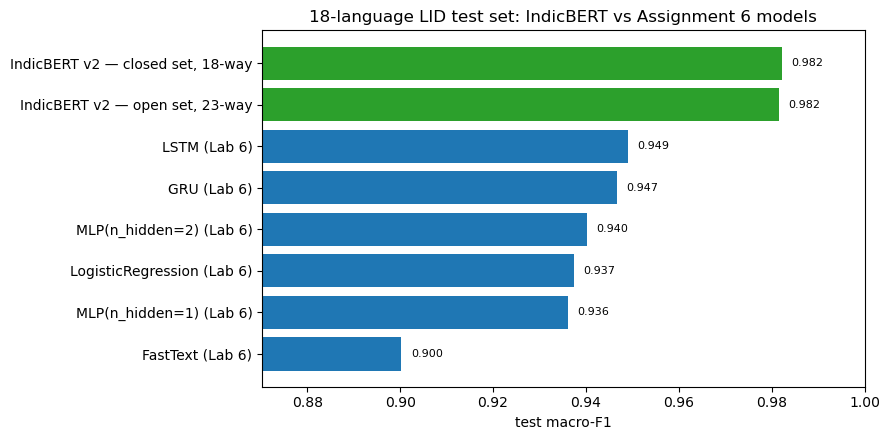

In [37]:
order = comparison.sort_values("test macro-F1")
colors = ["tab:green" if "IndicBERT" in m else "tab:blue" for m in order.model]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order.model, order["test macro-F1"], color=colors)
for y, v in enumerate(order["test macro-F1"]):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(order["test macro-F1"].min() - 0.03, 1.0)
ax.set_xlabel("test macro-F1"); ax.set_title("18-language LID test set: IndicBERT vs Assignment 6 models")
plt.tight_layout(); plt.show()

In [38]:
# Per-language F1 on the Devanagari languages, where all earlier models struggled
deva = [lab for lab in lab6_labels if lab.endswith("_Deva")]
f1_table = {f"{name}": macro_f1_score(y_sub, pred, len(lab6_labels))[1] for name, pred in lab6_preds.items()}
f1_table["IndicBERT (closed)"] = macro_f1_score(y_sub, closed_pred, len(lab6_labels))[1]
f1_table = pd.DataFrame(f1_table, index=lab6_labels)
f1_table.loc[deva].round(3)

,LogisticRegression,MLP(n_hidden=1),MLP(n_hidden=2),LSTM,GRU,FastText,IndicBERT (closed)
gom_Deva,0.688,0.634,0.664,0.734,0.670,0.688,0.850
hin_Deva,0.964,0.965,0.970,0.965,0.965,0.945,0.995
mai_Deva,0.893,0.893,0.896,0.908,0.929,0.898,0.990
mar_Deva,0.656,0.686,0.677,0.724,0.717,0.739,0.854
npi_Deva,0.936,0.916,0.931,0.969,0.965,0.940,1.000
san_Deva,0.919,0.922,0.913,0.919,0.939,0.794,0.995
snd_Deva,0.980,0.985,0.985,0.990,0.995,0.980,1.000


In [39]:
pd.DataFrame({"y_true": test_df.label, "y_pred": [IDX2LABEL[i] for i in y_pred]}).to_csv(
    f"{ARTIFACTS_DIR}/indicbert_test_predictions.csv", index=False)
comparison.to_csv(f"{ARTIFACTS_DIR}/comparison_18_languages.csv", index=False)
full.to_csv(f"{ARTIFACTS_DIR}/comparison_23_languages.csv")
report.to_csv(f"{ARTIFACTS_DIR}/indicbert_test_report.csv")

## 7. Result analysis

- **IndicBERT v2 is the best model:** test accuracy **0.9813** and macro-F1 **0.9813** on all 23 languages. That is +3.6 points over TF-IDF + LR (Lab 1, 0.9454). On the 18-language subset it scores 0.982, against 0.949 for the best Lab 6 model (LSTM), with GRU, MLP, LR and FastText (0.900) below that.
- **Training:** validation macro-F1 was 0.973 after 1 epoch and 0.979 after 3, so most of the gain comes from pretraining. This held even with the token embeddings frozen (86M of 278M parameters trained, 24.8 min on MPS).
- **Per language:** 15 of 23 languages score F1 = 1.0, including every non-Devanagari language except Khasi (0.985). The largest gains are on the hard Devanagari languages: Konkani (gom) 0.63 → 0.84, Marathi 0.72 → 0.85, Hindi 0.87 → 0.96 and Bodo 0.90 → 0.96. Pretraining on IndicCorp gives the model real knowledge of each language's vocabulary and grammar, not just character n-grams.
- **Remaining errors:** 28 of the 43 errors are Marathi ↔ Konkani, which share script, vocabulary and much morphology. Bodo → Hindi (6) is the next largest. Open-set (23-way) and closed-set (18-way) scores are nearly the same (0.9816 vs 0.9822), so the 5 extra languages rarely cause confusions.
- **Trade-off:** IndicBERT is far larger and much slower to train and run than TF-IDF + LR, which comes within about 4 points. For high-accuracy LID among closely related Devanagari languages, the fine-tuned transformer is clearly better.